Modules reloaded successfully.
Using device: cpu

Real audio directory:
/Users/melaniequ/Voice Cloning and Fake Audio Detection/data/processed/commonvoice

Fake audio directory:
/Users/melaniequ/Voice Cloning and Fake Audio Detection/data/processed/generated

Original real files: 29321
Original fake files: 741


/Users/melaniequ/vcfad-tts/lib/python3.10/site-packages/librosa/core/intervals.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


Skipping short audio (0.416s): ../data/processed/commonvoice/train/mcv-sps-st-09-2025/sps-corpus-1.0-2025-09-05-kcn/audios/spontaneous-speech-kcn-23535.mp3
Skipping short audio (0.372s): ../data/processed/commonvoice/train/mcv-sps-st-09-2025/sps-corpus-1.0-2025-09-05-kcn/audios/spontaneous-speech-kcn-23364.wav
Skipping short audio (0.316s): ../data/processed/commonvoice/train/mcv-sps-st-09-2025/sps-corpus-1.0-2025-09-05-kcn/audios/spontaneous-speech-kcn-23398.wav
Skipping short audio (0.256s): ../data/processed/commonvoice/train/mcv-sps-st-09-2025/sps-corpus-1.0-2025-09-05-kcn/audios/spontaneous-speech-kcn-23574.wav
Skipping short audio (0.108s): ../data/processed/commonvoice/train/mcv-sps-st-09-2025/sps-corpus-1.0-2025-09-05-kcn/audios/spontaneous-speech-kcn-22850.mp3
Skipping short audio (0.224s): ../data/processed/commonvoice/train/mcv-sps-st-09-2025/sps-corpus-1.0-2025-09-05-kcn/audios/spontaneous-speech-kcn-22803.wav
Skipping short audio (0.372s): ../data/processed/commonvoice/tra

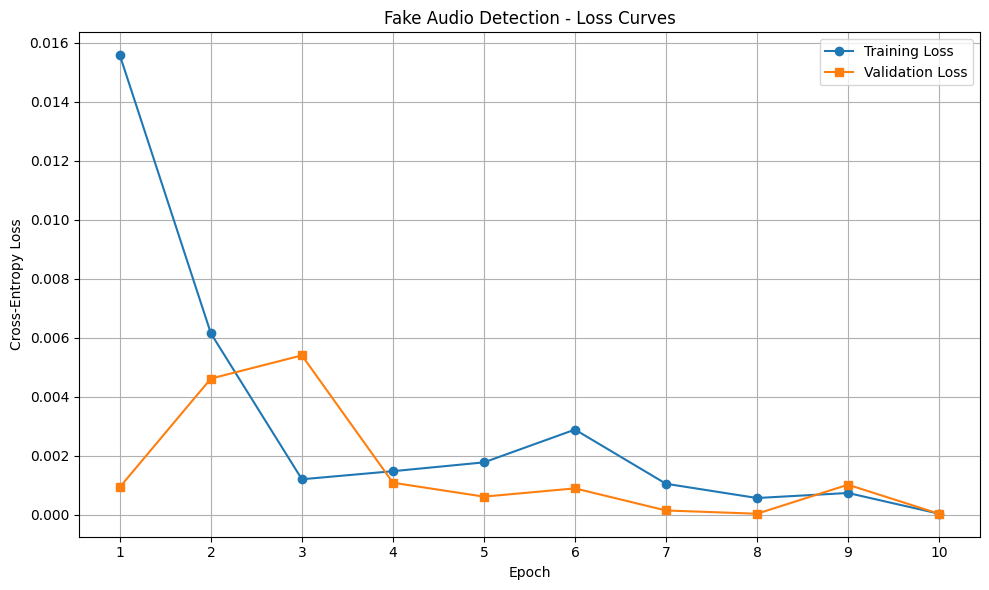

Loss plot saved to: ../models/loss_curve.png


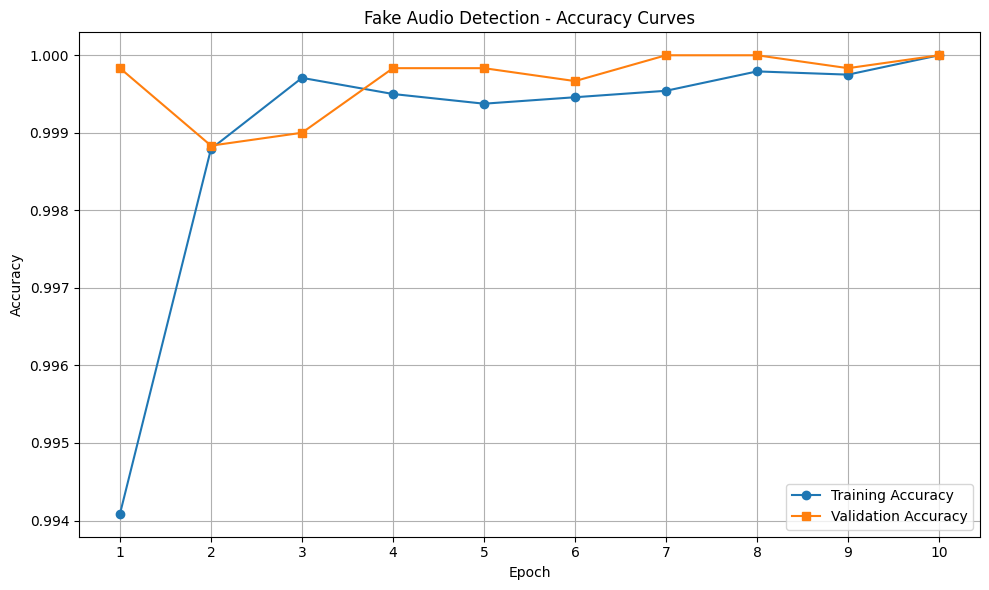

Accuracy plot saved to: ../models/accuracy_curve.png


In [1]:

import torch
import matplotlib.pyplot as plt
import importlib
from pathlib import Path
from torch.utils.data import DataLoader, random_split

import dataset as dataset_module
import model as model_module

# =========================================================
# RELOAD MODULES
# =========================================================

importlib.reload(dataset_module)
importlib.reload(model_module)

FakeAudioDataset = dataset_module.FakeAudioDataset
FakeAudioCNN = model_module.FakeAudioCNN

print("Modules reloaded successfully.")

# =========================================================
# CONFIGURATION
# =========================================================

REAL_DIR = "../data/processed/commonvoice"
FAKE_DIR = "../data/processed/generated"
MODEL_OUTPUT = "../models/fake_audio_detector.pt"
LOSS_PLOT = "../models/loss_curve.png"

BATCH_SIZE = 16
EPOCHS = 10
LEARNING_RATE = 0.001
TRAIN_RATIO = 0.8

# =========================================================
# DEVICE
# =========================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

# =========================================================
# DATASET
# =========================================================

dataset = FakeAudioDataset(
    real_dir=REAL_DIR,
    fake_dir=FAKE_DIR
)

print("Total dataset samples:", len(dataset))

if len(dataset) < 2:
    raise ValueError("Dataset must contain at least 2 samples.")

# =========================================================
# TRAIN / VALIDATION SPLIT
# =========================================================

train_size = int(TRAIN_RATIO * len(dataset))
val_size = len(dataset) - train_size

generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size],
    generator=generator
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

# =========================================================
# MODEL, LOSS, AND OPTIMIZER
# =========================================================

model = FakeAudioCNN().to(device)

criterion = torch.nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

# =========================================================
# LOSS AND ACCURACY HISTORY
# =========================================================

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

# =========================================================
# TRAINING
# =========================================================

for epoch in range(EPOCHS):

    model.train()

    train_loss_total = 0.0
    train_correct = 0
    train_total = 0

    for features, labels in train_loader:

        features = features.to(device)
        labels = labels.to(device).long()

        optimizer.zero_grad()

        outputs = model(features)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)

        # Weight batch loss by its number of samples.
        train_loss_total += loss.item() * batch_size

        predictions = torch.argmax(outputs, dim=1)

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += batch_size

    epoch_train_loss = train_loss_total / train_total
    train_accuracy = train_correct / train_total

    train_losses.append(epoch_train_loss)
    train_accuracies.append(train_accuracy)

    # =====================================================
    # VALIDATION
    # =====================================================

    model.eval()

    val_loss_total = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for features, labels in val_loader:

            features = features.to(device)
            labels = labels.to(device).long()

            outputs = model(features)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)

            val_loss_total += loss.item() * batch_size

            predictions = torch.argmax(outputs, dim=1)

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += batch_size

    epoch_val_loss = val_loss_total / val_total
    val_accuracy = val_correct / val_total

    val_losses.append(epoch_val_loss)
    val_accuracies.append(val_accuracy)

    # =====================================================
    # PRINT EPOCH RESULTS
    # =====================================================

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

# =========================================================
# SAVE TRAINED MODEL
# =========================================================

model_path = Path(MODEL_OUTPUT)
model_path.parent.mkdir(parents=True, exist_ok=True)

torch.save(model.state_dict(), model_path)

print(f"\nModel saved to: {model_path}")

# =========================================================
# PLOT TRAINING AND VALIDATION LOSS
# =========================================================

epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(10, 6))

plt.plot(
    epochs_range,
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    val_losses,
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Fake Audio Detection - Loss Curves")

plt.xticks(list(epochs_range))
plt.legend()
plt.grid(True)
plt.tight_layout()

plot_path = Path(LOSS_PLOT)
plot_path.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Loss plot saved to: {plot_path}")

# =========================================================
# PLOT TRAINING AND VALIDATION ACCURACY
# =========================================================

plt.figure(figsize=(10, 6))

plt.plot(
    epochs_range,
    train_accuracies,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    val_accuracies,
    marker="s",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Fake Audio Detection - Accuracy Curves")

plt.xticks(list(epochs_range))
plt.legend()
plt.grid(True)
plt.tight_layout()

accuracy_path = Path("../models/accuracy_curve.png")
plt.savefig(accuracy_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Accuracy plot saved to: {accuracy_path}")
